In [1]:
# ---- Device: must run before anything imports jax ----
from devices import use_device
use_device("auto")      # "auto" | "gpu" | "cpu"  (restart the kernel to switch)

import os
# os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false") # If sharing GPU with other processes
os.environ.setdefault("XLA_PYTHON_CLIENT_MEM_FRACTION", "0.2") # If not set, JAX automatically grabs 75% of the GPU's total memory, which can be excessive
# os.environ["XLA_FLAGS"] = (os.environ.get("XLA_FLAGS", "") + " --xla_gpu_deterministic_ops=true").strip() #force deterministic computation on GPU
import jax, numpyro
import jax.numpy as jnp
import numpy as np
print("JAX:", jax.__version__)
print(jax.default_backend())   # 'gpu' or 'cpu': where JAX runs things by default
print(jax.devices())           # e.g. [CudaDevice(id=0)] for the GPU, or 8 CpuDevices
print("local device count:", jax.local_device_count())

import matplotlib.pyplot as plt
import arviz as az
import arviz_base
import arviz_plots as azp
from postprocess import pointwise_log_lik, combine_chains, order_pulses

import numpyro.distributions as dist

from model import (
    setup_model,
    running_power_law_log_sed,
)
from data import (
    prepare_burst,
)
from run import (
    maxL_iterative_pulse_fit,
    run_fit,
    set_priors
)
from results import (
    save_run,
)
from plotting import (
    plot_burst_TD,
    plot_burst_FD,
    model_from_draw,
    plot_fit_TD,
)

from pathlib import Path

FRBayes: running on the GPU


/arc/home/hsiegel/FRBayes/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


JAX: 0.11.2
gpu
[CudaDevice(id=0)]
local device count: 1


In [2]:
# from numpyro.contrib.nested_sampling import NestedSampler   # jaxns switches JAX to float64 on this import

820 good channels -> 51 blocks of 16 (4 dropped); block span median 6.641 MHz, max 36.719 MHz
noise estimated from 65 of 329 time bins (first 20% of the segment)
Fourier truncation: keeping 19 of 165 bins (up to 5.6 kHz of 48.7 kHz)
channel weights from 5 significant box(es) of an excess-power search of the data; weighted mean frequency 455.1 MHz, reference frequency 449.3 MHz
Fourier truncation check: in the significant boxes, SNR 227.1 in the retained bins, 234.1 with every bin (gain 6.96); excess power above the cut 3209, noise sd 154
burst data shape = (51, 19)


/arc/home/hsiegel/FRBayes/src/data.py:277: UserWarning: the bins above the Fourier cut hold part of the burst: keeping them would raise its SNR from 227.1 to 234.1. Prepare the burst with a smaller fd_downsample.
  warnings.warn(f"the bins above the Fourier cut hold part of the burst: keeping them would raise its SNR "


rebaseline: each channel's noise-window mean subtracted, for display only.


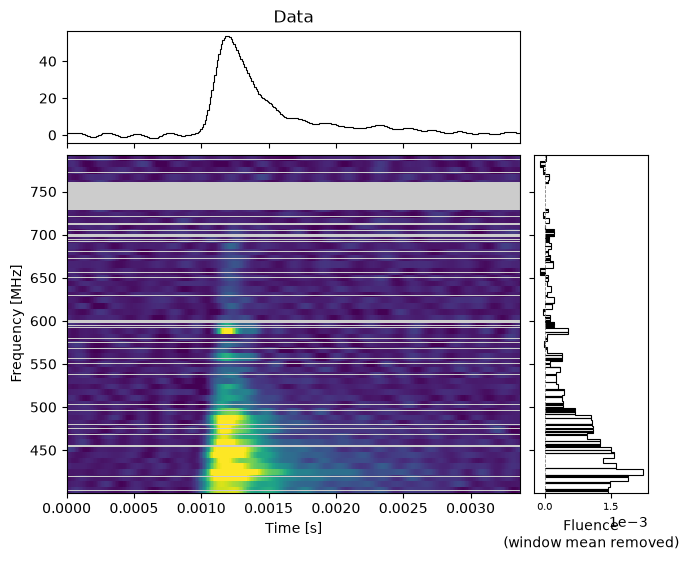

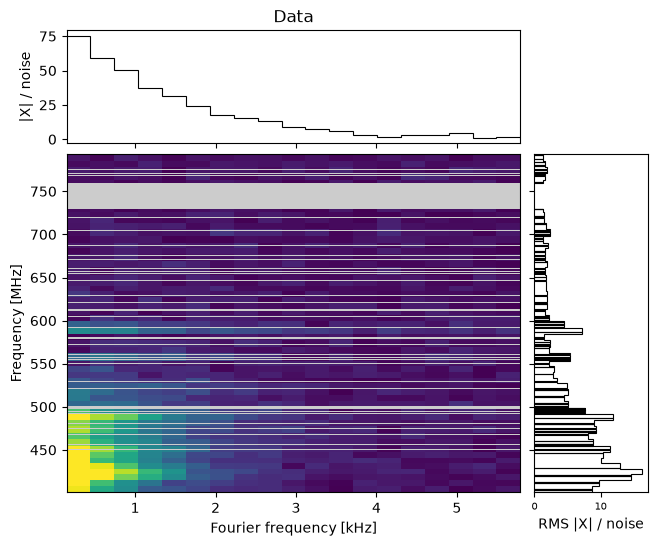

In [3]:
PROJECT  = Path("/arc/home/hsiegel/FRBayes")

# event_id = "22310619_BB" #Multi-pulse, 4 pulses
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# "22310619_BB"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=16,                # frequency channels averaged per block
#     fd_downsample=8,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

# event_id = "27687783_BB" #Multi-pulse, many
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=16,                # frequency channels averaged per block
#     fd_downsample=64,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

# event_id = "23438043_BB" # Single-pulse, Narrow SED with scatter
# data_path = PROJECT / "data" / f"event_{event_id}.npz"
# burst = prepare_burst(
#     path=data_path,
#     n_avg=16,                # frequency channels averaged per block
#     fd_downsample=8,        # downsampling factor of high frequency FD bins
#     toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
#     noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
#     verbose=True,
# )

event_id = "22154974_BB" # Single-pulse, Broadband with scatter
data_path = PROJECT / "data" / f"event_{event_id}.npz"
burst = prepare_burst(
    path=data_path,
    n_avg=16,                # frequency channels averaged per block
    fd_downsample=8,        # downsampling factor of high frequency FD bins
    toa=None,               # if no upstream TOA, falls back to noise_fraction below to estimate noise
    noise_fraction=0.2,     # fraction of the segment used for the off-pulse noise estimate
    verbose=True,
)

# How the data were dedispersed before FRBayes; save_run refuses to save without both
dm_dedispersion = None          # pc cm^-3 (fill in)
dedispersion_ref_freq = None    # MHz the channels were aligned to; np.inf for infinite frequency (fill in)

out_path  = PROJECT / "runs" / f"event_{event_id}.nc"
out_path.parent.mkdir(parents=True, exist_ok=True)     # create runs/ if it doesn't exist

print("burst data shape =",burst.data_fd.shape)
plot_burst_TD(burst);                                          # data, in time
plot_burst_FD(burst);                                          # data, in Fourier space

# Jaxns slice nested sample

In [4]:
# import time
# import numpy as np
# import jax
# import numpyro.distributions as dist
# from model import setup_model, running_power_law_log_sed
# from run import set_priors
# from likelihood import FD_gaussianlikelihood

# constants_dict = {
#     "freq_channels_ref": burst.freq_channels_ref,
#     "DM_incoherent": 0.0,          # data are coherently dedispersed, so no intra-channel smearing remains
#     "channel_width": burst.channel_width,
#     "det_response": 1.0,           # beam response, set to 1 if not used
# }
# single_pulse_fn = setup_model(
#     constants_dict=constants_dict,
#     freqs_channels=burst.freq_channels,
#     times=burst.times,
#     sed_fn=running_power_law_log_sed,
#     fourier_freqs=burst.fourier_freqs,
# )

# # the same priors and likelihood arguments the 1-pulse ITFit step uses
# priors = set_priors(burst, single_pulse_fn, 1, s_opt=100.0,
#                     gamma=dist.Uniform(-10.0, 200.0), beta=dist.Uniform(-200.0, 10.0))
# model_kwargs = dict(data_fd=burst.data_fd, sigma_noise_fd=burst.sigma_noise_fd, n_pulses=1, priors=priors,
#                     single_pulse_fn=single_pulse_fn, spectral_coeff_map=None, shared_params=("DM", "tau_ref"),
#                     ordered_times=False, repulsion={})

# ns = NestedSampler(FD_gaussianlikelihood, constructor_kwargs=dict(max_samples=1e6))   # default: 25 live points per parameter
# t0 = time.time()
# ns.run(jax.random.PRNGKey(2), **model_kwargs)
# print(f"nested sampling: {time.time() - t0:.0f} s")
# ns.print_summary()

In [5]:
import time
import jax
import numpyro.distributions as dist
from run import set_priors
from likelihood import FD_gaussianlikelihood
import numpyro.distributions as dist


constants_dict = {
    "freq_channels_ref": burst.freq_channels_ref,
    "DM_incoherent": 0.0,          # data are coherently dedispersed, so no intra-channel smearing remains
    "channel_width": burst.channel_width,
    "det_response": 1.0,           # beam response, set to 1 if not used
}
single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=running_power_law_log_sed,
    fourier_freqs=burst.fourier_freqs,
)


N_PULSES = 4
priors = set_priors(burst, single_pulse_fn, N_PULSES, s_opt=100.0,
                    gamma=dist.Uniform(-10.0, 200.0), beta=dist.Uniform(-200.0, 10.0))
model_kwargs = dict(data_fd=burst.data_fd, sigma_noise_fd=burst.sigma_noise_fd, n_pulses=N_PULSES, priors=priors,
                    single_pulse_fn=single_pulse_fn, spectral_coeff_map=None, shared_params=("DM", "tau_ref"),
                    ordered_times=False, repulsion={})

ns = NestedSampler(FD_gaussianlikelihood,
                   constructor_kwargs=dict(max_samples=1e6, verbose=False))     # 25 live points per parameter (550)
t0 = time.time()
ns.run(jax.random.PRNGKey(2), **model_kwargs)
print(f"nested sampling, {N_PULSES} pulses: {time.time() - t0:.0f} s")
ns.print_summary()

prior being set with bounds:
sigma_min = 2.6890819021378463e-05 
sigma_max = 0.0014643199911006377 
tau_ref_min = 0.0 
tau_ref_max = 0.0011280246028912404
mean_arrival_time: Uniform(low=0, high=0.00877568)
DM: Uniform(low=-0.234355, high=0.234355)
sigma: LogUniform(low=2.68908e-05, high=0.00146432)
tau_ref: Uniform(low=0, high=0.00112802)
A_snr: HalfNormal(scale=100)
gamma: Uniform(low=-10, high=200)
beta: Uniform(low=-200, high=10)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)


INFO:jaxns:Number of Markov-chains set to: 550


sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
sampling the amplitude as A_snr (SNR units)
nested sampling, 4 pulses: 1125 s
--------
Termination Conditions:
Small remaining evidence
--------
likelihood evals: 20068033
samples: 37950
phantom samples: 0
likelihood evals / sample: 528.8
phantom fraction (%): 0.0%
--------
logZ=-3802.74 +- 0.42
max(logL)=-3723.86
H=-66.73
ESS=2041
--------
A[#]: mean +- std.dev. | 10%ile / 50%ile / 90%ile | MAP est. | max(L) est.
A[0]: 0.000157 +- 2.4e-05 | 0.000127 / 0.000157 / 0.000186 | 0.000152 | 0.000152
A[1]: 3e-15 +- 1.4e-14 | 0.0 / 0.0 / 5e-15 | 2.84e-13 | 2.84e-13
A[2]: 1.5e-13 +- 5.1e-13 | 0.0 / 0.0 / 4.2e-13 | 7.5e-13 | 7.5e-13
A[3]: 0.0001134 +- 5.4e-06 | 0.0001065 / 0.0001132 / 0.000120

# maxL itfit

In [4]:
constants_dict = {
    "freq_channels_ref": burst.freq_channels_ref,
    "DM_incoherent": 0.0,                   # 0 means coherently dedispersed: only the fitted residual DM smears within a channel
    "freq_members": burst.freq_members,     # raw channels averaged into each channel, for the smearing
    "raw_channel_width": burst.raw_dnu,     # width of one raw channel (MHz)
    "det_response": 1.0,                    # beam response, set to 1 if not used
}
single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=burst.freq_channels,
    times=burst.times,
    sed_fn=running_power_law_log_sed,
    fourier_freqs=burst.fourier_freqs,
)

maxL_iterative_pulse_fit: snr_min 8, accept a pulse if ln L rises by >= 37 (snr_min^2 / 2 + 5 parameters), minimum box width 5 channels, up to 15 pulses, seed 2, tau profile over at least 8 values from 0.1 dt plus 0.001 dt; priors:
  mean_arrival_time: Uniform(low=0, high=0.00335872)
  DM: Uniform(low=-0.0898636, high=0.0898636)
  sigma: LogUniform(low=2.82203e-05, high=0.000561493)
  tau_ref: Uniform(low=0, high=0.00110217)
  gamma: Uniform(low=-225.304, high=225.304)
  beta: Uniform(low=-200, high=10)
  A_snr: HalfNormal(scale=100)
maxL_fit: likelihood FD_gaussianlikelihood, parameterizing fluence in units of SNR as A_snr
maxL_fit: 1 pulse(s), 64 starts (0 warm) x 9 tau values: best ln L + repulsion = -2263.0 (start 34, random); 27 start(s) within 1 nat; 44 s
  tau profile (tau_ref held fixed):   0.0102us:-4289.1  1.02us:-4289.1  2.78us:-4289.0  7.52us:-4287.3  20.4us:-4270.6  55.3us:-4115.3  150us:-3226.8  406us:-2302.4  1.1e+03us:-4605.5
  best run: tau_ref 354.9 us after release
R

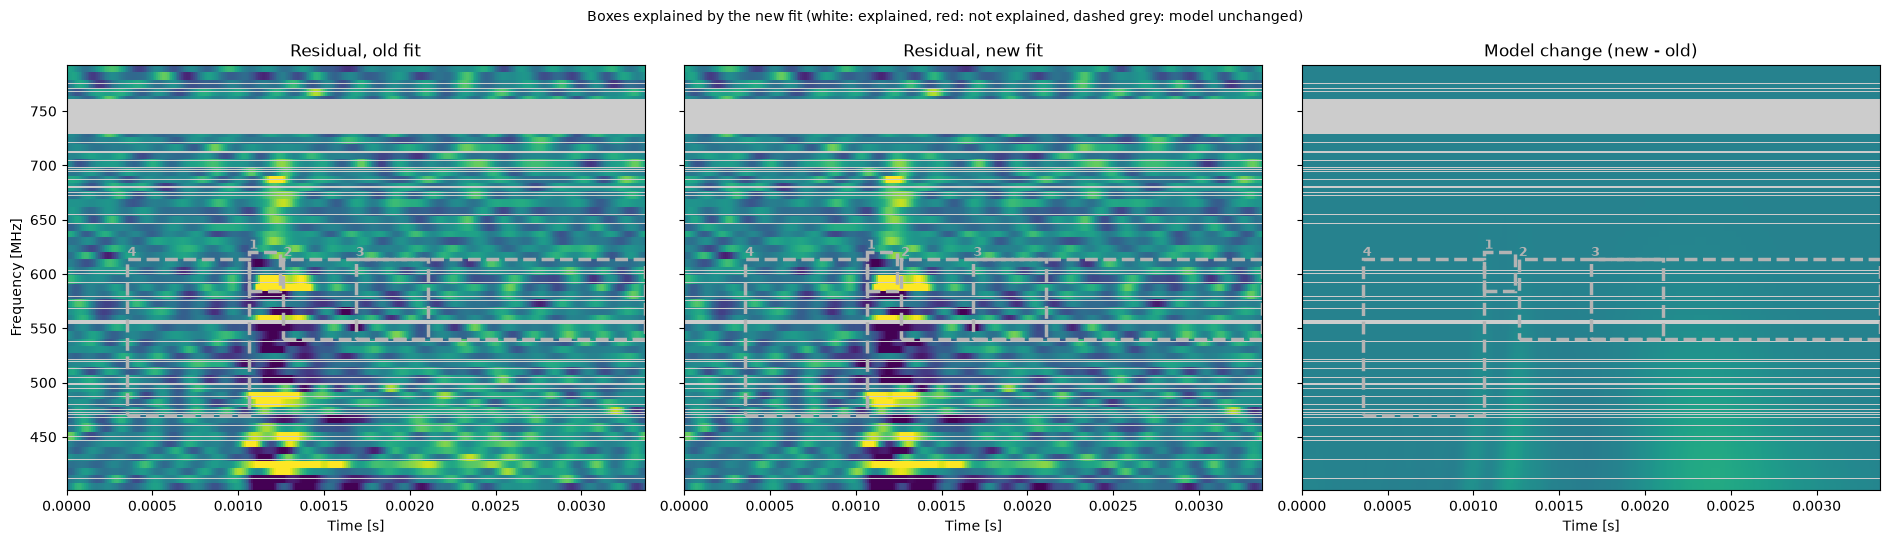

1 -> 2 pulses: delta ln L = 63.4 (need 37), explains leftover signal: False -> reject
final: 1 pulses (2-pulse fit rejected: it explains no flagged leftover signal); optimizer time 114 s
rebaseline: each channel's noise-window mean subtracted, for display only.


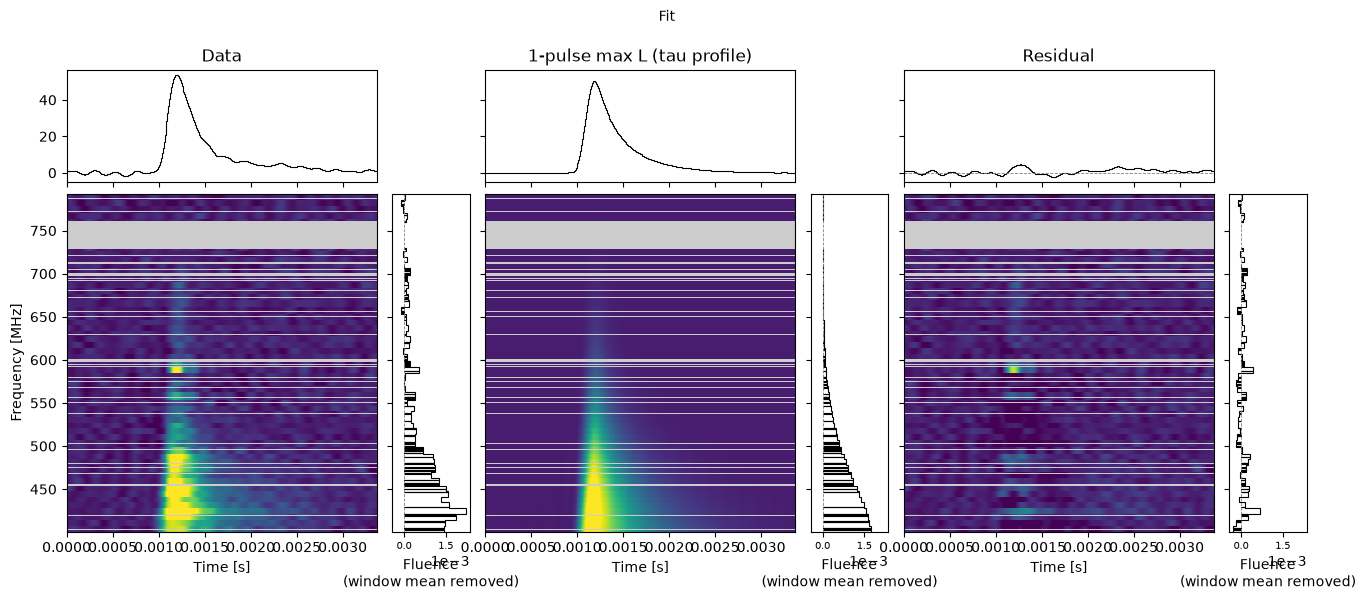

run_fit: likelihood FD_gaussianlikelihood, parameterizing fluence in units of SNR as A_snr, seed 2; priors:
  mean_arrival_time: Uniform(low=0, high=0.00335872)
  DM: Uniform(low=-0.0898636, high=0.0898636)
  sigma: LogUniform(low=2.82203e-05, high=0.000561493)
  tau_ref: Uniform(low=0, high=0.00110217)
  gamma: Uniform(low=-225.304, high=225.304)
  beta: Uniform(low=-200, high=10)
  A_snr: HalfNormal(scale=100)


sample: 100%|██████████| 700/700 [01:23<00:00,  8.41it/s]


In [5]:
res_ml = maxL_iterative_pulse_fit(
    burst, single_pulse_fn,
    snr_min=8.0, n_max=15, num_starts=64, seed=2, plot_steps=True,
    tau_profile=8, tau_parallel=True,                      # at least 8 tau values, 0.1 dt to the prior maximum
    repulsion={},
    n_adam=1000,
    n_polish=500,
    split_starts=True,
    box_spectrum=True,
)   # default priors: beta ~ U(-200, 10), gamma ~ U(-gamma_max, gamma_max) from the band
M, M_pulses = model_from_draw(single_pulse_fn, res_ml["fit"]["post"], 0)
plot_fit_TD(burst, M, M_pulses, title_model=f"{res_ml['n_pulses']}-pulse max L (tau profile)");

# NUTS on the kept fit, every chain started at the maxL optimum (same priors and likelihood settings)
mcmc = run_fit(burst, single_pulse_fn, res_ml["fit"]["priors"], maxL_start=res_ml,
               num_chains=64, num_warmup=500, num_samples=200, seed=2, repulsion={})

group_chains: 64 chains -> 1 mode(s) (pairs linked where every R-hat < 1.1)
  mode 0: chains [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63], largest R-hat within 1.055
  mode 0: peak log post +0.0, mean log-lik +0.0, 64 chain(s) -> kept
combine_chains: 12800 draws from mode 0
64 chains x 200 draws


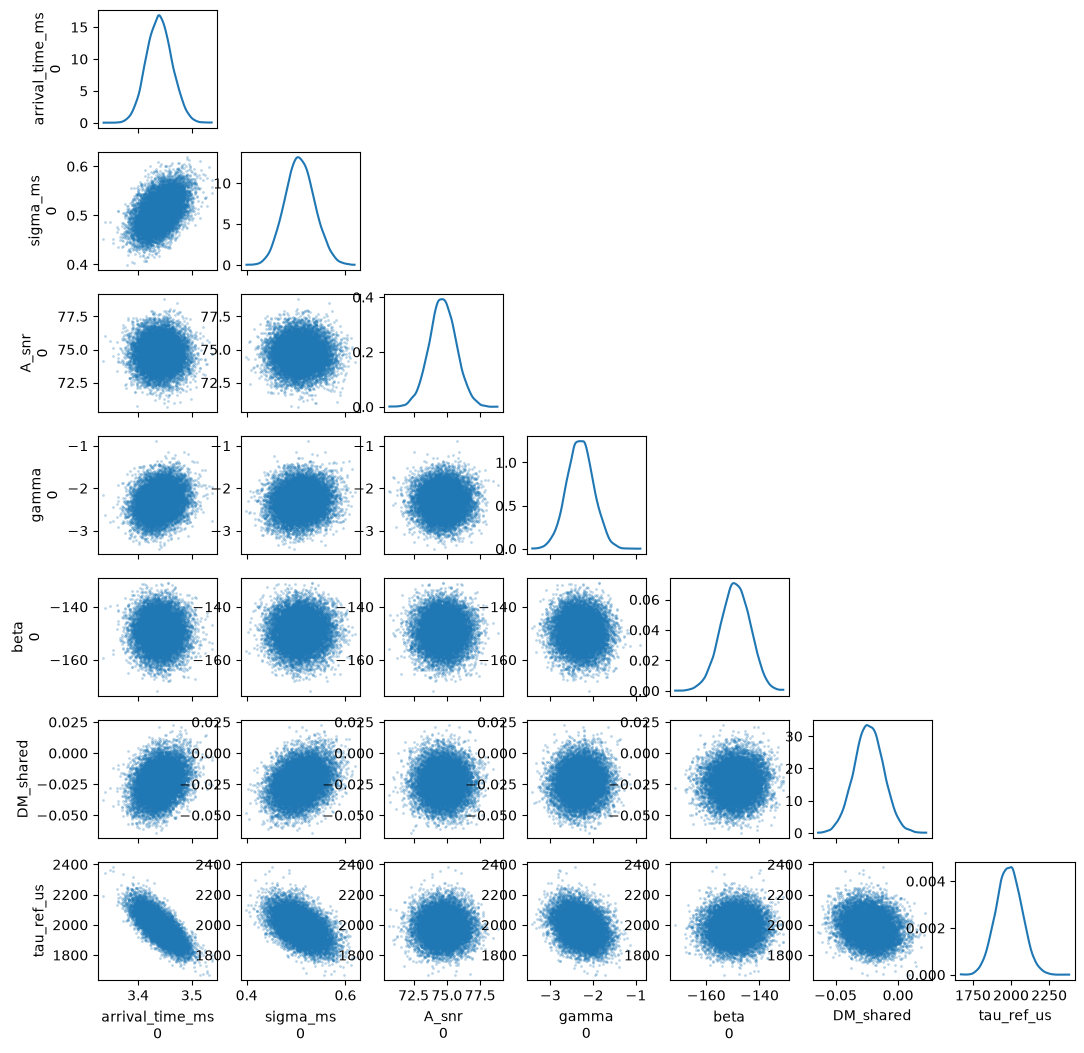

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
A[0],0.005906,0.000161,0.0057,0.0062,18435,10704,1.00,1.2e-06,1.4e-06
A_snr[0],74.69,1.01,73,76,22578,10789,1.00,0.0067,0.0091
DM_shared,-0.0234,0.0117,-0.042,-0.0048,19996,10936,1.00,8.2e-05,0.0001
beta[0],-149.11,5.52,-160,-140,17799,9458,1.01,0.042,0.049
gamma[0],-2.302,0.308,-2.8,-1.8,20275,10965,1.00,0.0022,0.0027
log_sed_peak[0],0.00682,0.00124,0.0048,0.0088,20087,10880,1.01,8.8e-06,1.1e-05
arrival_time_ms[0],3.4396,0.0238,3.4,3.5,19243,11554,1.00,0.00017,0.0002
sigma_ms[0],0.5077,0.03,0.46,0.56,18539,10829,1.00,0.00022,0.00026
snr_opt[0],12569,305,12000,13000,17415,10153,1.00,2.3,2.6
tau_ref_us,1987,84,1900,2100,17098,9878,1.00,0.65,0.75


In [12]:
run = mcmc                                 # <- the only line to change: a run_fit result (e.g. started with maxL_start=res_ml)
PULSE = 0                                  # which pulse to plot (0 = earliest)

# Combine the NUTS chains (grouping them into modes), then order every draw's pulses by arrival time
n = run.n_pulses
s = {k: np.asarray(v) for k, v in run.get_samples(group_by_chain=True).items()}
U = np.asarray(run.get_extra_fields(group_by_chain=True)["potential_energy"])
post, info = combine_chains(s, pointwise_log_lik(burst, single_pulse_fn, s, thin=1), U)
post = order_pulses({k: np.asarray(v) for k, v in post.items()}, verbose=False)

# Regroup the pooled draws by their source chain (for R-hat and ESS), in readable units
units = {"mean_arrival_time": ("arrival_time_ms", 1e3), "sigma": ("sigma_ms", 1e3), "tau_ref": ("tau_ref_us", 1e6)}
order = np.lexsort((info["draw"], info["chain"]))
chains, counts = np.unique(np.asarray(info["chain"])[order], return_counts=True)
by_chain = np.all(counts == counts[0])
shape = (len(chains), counts[0]) if by_chain else (1, len(order))
data, dims = {}, {}
for k, v in post.items():
    v = np.asarray(v, dtype=float)
    if (not k.endswith("_shared") and f"{k}_shared" in post) or (v.ndim == 2 and v.shape[1] != n):
        continue                           # copies of shared parameters, and pair sites like toa_separation
    name, unit = units.get(k.removesuffix("_shared"), (k, 1.0))
    data[name] = (v[order] * unit).reshape(shape + v.shape[1:])
    if v.ndim == 2:
        dims[name] = ["pulse"]
dt = az.from_dict({"posterior": data}, dims=dims, coords={"pulse": np.arange(n)})
print(f"{len(chains)} chains x {counts[0]} draws" if by_chain else
      f"unequal draws per chain: summarized as one sequence of {len(order)} draws, so R-hat is nan")

# Corner plot of one pulse with the shared parameters
pulse_vars = [v for v in ["arrival_time_ms", "sigma_ms", "A_snr", "gamma", "beta", "delta"] if v in dt.posterior]
shared_vars = [v for v in ["DM_shared", "tau_ref_us"] if v in dt.posterior]
names = pulse_vars + shared_vars
arviz_base.rcParams["plot.max_subplots"] = 300
azp.plot_pair(dt, var_names=names, coords={"pulse": [PULSE]}, marginal=True, triangle="lower",
              visuals={"scatter": {"alpha": 0.3, "size": 4}},
              figure_kwargs={"figsize": (1.8 * len(names), 1.8 * len(names))})
plt.show()

az.summary(dt, kind="all")

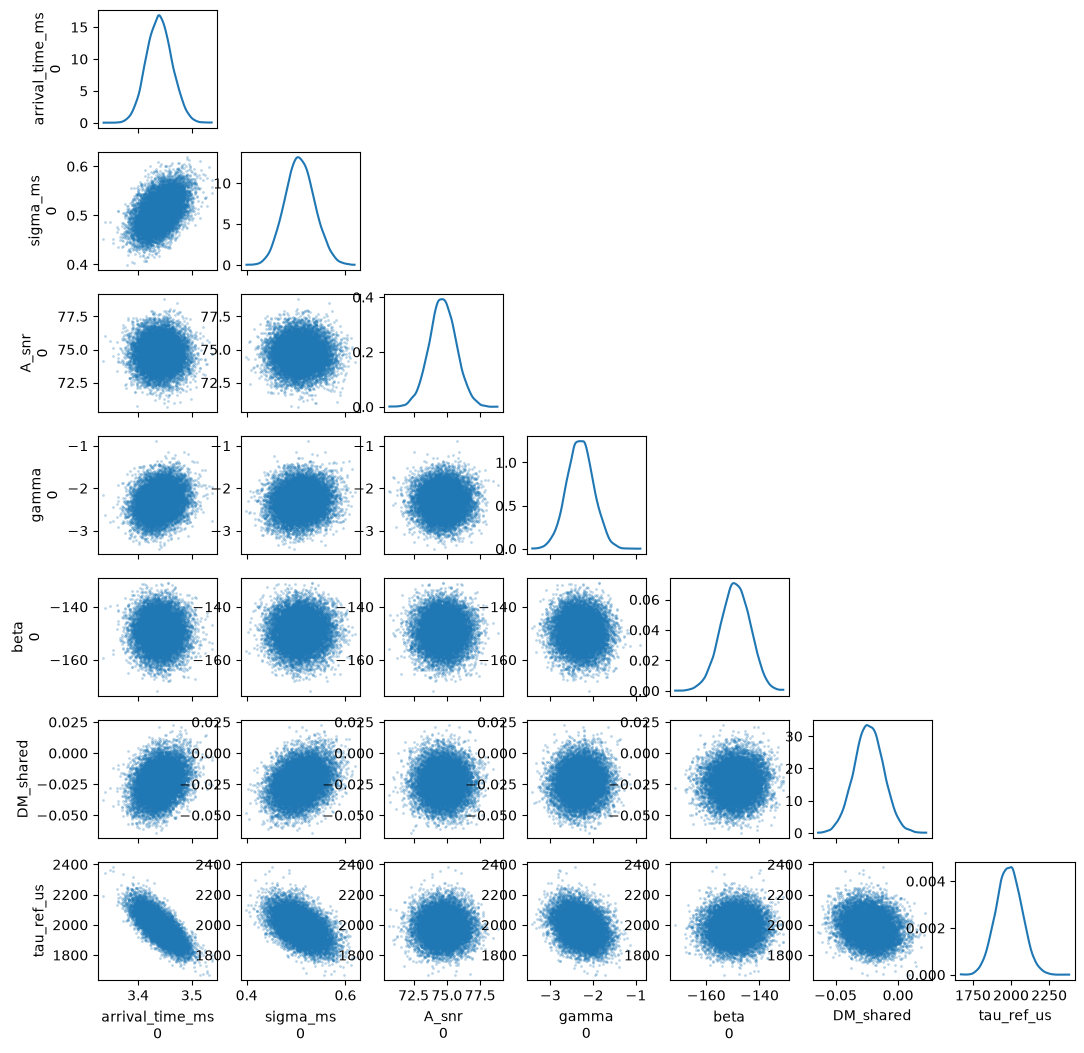

In [13]:
# Corner plot of one pulse with the shared parameters
PULSE = 0
pulse_vars = [v for v in ["arrival_time_ms", "sigma_ms", "A_snr", "gamma", "beta", "delta"] if v in dt.posterior]
shared_vars = [v for v in ["DM_shared", "tau_ref_us"] if v in dt.posterior]
names = pulse_vars + shared_vars
arviz_base.rcParams["plot.max_subplots"] = 300
azp.plot_pair(dt, var_names=names, coords={"pulse": [PULSE]}, marginal=True, triangle="lower",
              visuals={"scatter": {"alpha": 0.3, "size": 4}},
              figure_kwargs={"figsize": (1.8 * len(names), 1.8 * len(names))})
plt.show()


In [14]:
stats = jax.devices()[0].memory_stats()
print(f"peak {stats['peak_bytes_in_use'] / 1e9:.2f} GB of {stats['bytes_limit'] / 1e9:.2f} GB")

peak 0.21 GB of 2.31 GB
